Installing Libs and Set up

In [1]:
!pip install -q transformers datasets accelerate

import random
import numpy as np
import torch

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
print("Libraries installed and seed set to 42.")

Libraries installed and seed set to 42.


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
import os

os.environ['KAGGLE_USERNAME'] = "binhuang5"
os.environ['KAGGLE_KEY'] = "" # My API Key has been redacted for safety.
# Please ensure your kaggle.json is uploaded in order to run this notebook.

!kaggle datasets download -d lakshmi25npathi/imdb-dataset-of-50k-movie-reviews --unzip

print("\nFiles in directory:")
!ls -l

Dataset URL: https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews
License(s): other
100% 25.7M/25.7M [00:00<00:00, 96.3MB/s]


Files in directory:
total 64668
-rw-r--r-- 1 root root 66212309 Oct 25 16:14 'IMDB Dataset.csv'
drwxr-xr-x 1 root root     4096 Oct 21 13:28  sample_data


Loading data and understanding it.

In [4]:
import pandas as pd
from IPython.display import display

df = pd.read_csv('IMDB Dataset.csv')

print(f"Original shape: {df.shape}")
display(df.head(3))

Original shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive


Dropping duplicates

In [5]:
duplicates = df.duplicated().sum()
print(f"Duplicates found: {duplicates}")

if duplicates > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Shape after dropping duplicates: {df.shape}")

Duplicates found: 418
Shape after dropping duplicates: (49582, 2)


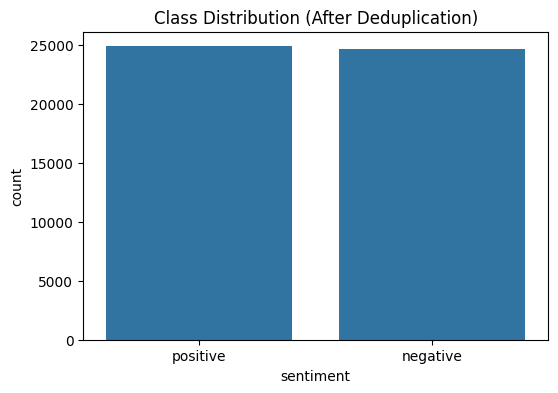


Exact class counts:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='sentiment')
plt.title("Class Distribution (After Deduplication)")
plt.show()

print("\nExact class counts:")
print(df['sentiment'].value_counts())

Train-Test Split

In [7]:
from sklearn.model_selection import train_test_split

# We use a 80/20 split. random_state=42 ensures reproducibility.
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    df['review'], df['sentiment'], test_size=0.2, random_state=42, stratify=df['sentiment']
)

print(f"Training set size: {len(X_train_raw)}")
print(f"Test set size: {len(X_test_raw)}")

Training set size: 39665
Test set size: 9917


Text Processing for Baseline

In [8]:
import re

def clean_text_basic(text):
    text = text.lower()
    # Remove HTML breaks which are common in IMDB
    text = re.sub(r'<br\s*/?>', ' ', text)
    # Remove special characters
    text = re.sub(r'[^\w\s]', '', text)
    # Normalize spaces
    text = " ".join(text.split())
    return text

print("Cleaning training data...")
X_train_clean = X_train_raw.apply(clean_text_basic)
print("Cleaning test data...")
X_test_clean = X_test_raw.apply(clean_text_basic)
print("Cleaning complete.")

Cleaning training data...
Cleaning test data...
Cleaning complete.


Train and Evaluate Baseline (TF-IDF + LinearSVC)

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, f1_score

# TF-IDF Vectorization
tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train_clean)
X_test_tfidf = tfidf.transform(X_test_clean)

# Train SVM
print("Training LinearSVC baseline...")
svm_model = LinearSVC(random_state=42, dual=False)
svm_model.fit(X_train_tfidf, y_train_raw)

# Predict and Evaluate
y_pred_base = svm_model.predict(X_test_tfidf)
base_macro_f1 = f1_score(y_test_raw, y_pred_base, average='macro')

print("\n--- Baseline Model Performance ---")
print(classification_report(y_test_raw, y_pred_base))
print(f"Baseline Macro F1: {base_macro_f1:.4f}")

Training LinearSVC baseline...

--- Baseline Model Performance ---
              precision    recall  f1-score   support

    negative       0.90      0.89      0.90      4940
    positive       0.89      0.90      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917

Baseline Macro F1: 0.8961


Label Encoding and Hugging Face Dataset Setup

In [10]:
from datasets import Dataset

# Map labels: positive -> 1, negative -> 0
label_map = {'positive': 1, 'negative': 0}
y_train_int = y_train_raw.map(label_map)
y_test_int = y_test_raw.map(label_map)

# Create Hugging Face Dataset objects
train_dataset = Dataset.from_dict({'text': X_train_raw.tolist(), 'label': y_train_int.tolist()})
test_dataset = Dataset.from_dict({'text': X_test_raw.tolist(), 'label': y_test_int.tolist()})

print("Hugging Face Datasets created.")
print(f"Train size: {len(train_dataset)}, Test size: {len(test_dataset)}")

Hugging Face Datasets created.
Train size: 39665, Test size: 9917


DistilBERT Tokenization

In [11]:
from transformers import DistilBertTokenizerFast

print("Downloading DistilBERT tokenizer...")
tokenizer = DistilBertTokenizerFast.from_pretrained('distilbert-base-uncased')

def tokenize_function(examples):
    # Truncate to 512 tokens since reviews are long
    return tokenizer(examples['text'], padding='max_length', truncation=True, max_length=512)

print("Tokenizing training data (this may take a minute)...")
tokenized_train = train_dataset.map(tokenize_function, batched=True)

print("Tokenizing test data...")
tokenized_test = test_dataset.map(tokenize_function, batched=True)

print("Tokenization complete.")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizing training data (this may take a minute)...


Map:   0%|          | 0/39665 [00:00<?, ? examples/s]

Tokenizing test data...


Map:   0%|          | 0/9917 [00:00<?, ? examples/s]

Tokenization complete.


Load Model and Define Metrics

In [12]:
from transformers import DistilBertForSequenceClassification
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

print("Downloading DistilBERT model...")
# Initialize model with 2 labels for binary classification
model = DistilBertForSequenceClassification.from_pretrained(
    'distilbert-base-uncased',
    num_labels=2
)
model.to(device)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    # Calculate macro F1 and Accuracy
    f1 = f1_score(labels, predictions, average="macro")
    acc = accuracy_score(labels, predictions)

    return {"accuracy": acc, "f1": f1}

print("Model loaded and metrics defined.")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded and metrics defined.


Configure and Run Training

In [14]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="./results",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=1,
    weight_decay=0.01,
    eval_strategy="epoch", # <-- Error. Updated from evaluation_strategy
    save_strategy="epoch",
    fp16=True,
    logging_steps=200,
    seed=42,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    compute_metrics=compute_metrics
)

print("Starting training. This will show a progress bar and may take a little while...")
trainer.train()


Starting training. This will show a progress bar and may take a little while...


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.205372,0.183665,0.932843,0.932836


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2480, training_loss=0.23405811786651612, metrics={'train_runtime': 548.0121, 'train_samples_per_second': 72.38, 'train_steps_per_second': 4.525, 'total_flos': 5254319367690240.0, 'train_loss': 0.23405811786651612, 'epoch': 1.0})

DistilBERT Classification Report

In [15]:
import numpy as np
from sklearn.metrics import classification_report

print("Generating predictions on the test set...")
predictions = trainer.predict(tokenized_test)
y_pred_distilbert = np.argmax(predictions.predictions, axis=-1)

print("\n--- DistilBERT Model Performance ---")
# Using target_names to map 0 and 1 back to negative and positive
print(classification_report(y_test_int, y_pred_distilbert, target_names=['negative', 'positive']))

Generating predictions on the test set...



--- DistilBERT Model Performance ---
              precision    recall  f1-score   support

    negative       0.94      0.93      0.93      4940
    positive       0.93      0.94      0.93      4977

    accuracy                           0.93      9917
   macro avg       0.93      0.93      0.93      9917
weighted avg       0.93      0.93      0.93      9917



Confusion Matrix and Saving Artifacts

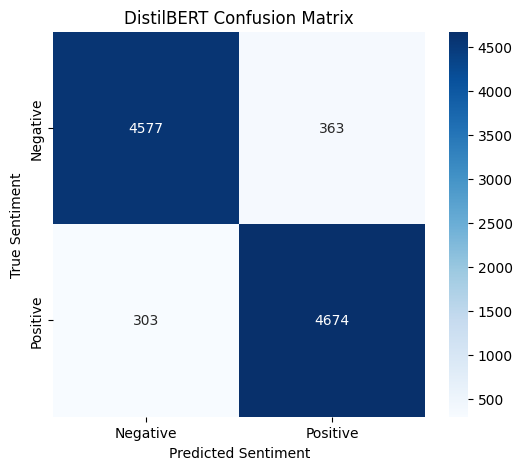

Confusion matrix saved to results/confusion_matrix.png


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import os

# Create results directory for GitHub submission
os.makedirs("results", exist_ok=True)

cm = confusion_matrix(y_test_int, y_pred_distilbert)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.title("DistilBERT Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("True Sentiment")

# Save the figure for your GitHub repo
plt.savefig("results/confusion_matrix.png", dpi=300, bbox_inches='tight')
plt.show()
print("Confusion matrix saved to results/confusion_matrix.png")

Sample Predictions

In [17]:
# Let's inspect a few real examples to see the model in action
print("Sample Predictions:\n")
for i in range(3):
    text = X_test_raw.iloc[i]
    true_label = "positive" if y_test_int.iloc[i] == 1 else "negative"
    pred_label = "positive" if y_pred_distilbert[i] == 1 else "negative"

    print(f"Review {i+1}: {text[:150]}...")
    print(f"True: {true_label} | Predicted: {pred_label}")
    print("-" * 50)

Sample Predictions:

Review 1: My wife and I watched this after DVR'ing it off of Encore action this past week. It has to be the worst horror flick either of us had ever seen. Predi...
True: negative | Predicted: negative
--------------------------------------------------
Review 2: I was surprised how much I enjoyed this. Sure it is a bit slow moving in parts, but what else would one expect from Rollin? Also there is plenty of nu...
True: positive | Predicted: positive
--------------------------------------------------
Review 3: Such a delightful movie! Very heart warming. One can't help falling in love with the character of Gigi. He's adorable as a child and grows into a sens...
True: positive | Predicted: positive
--------------------------------------------------


ROC Curve and AUC

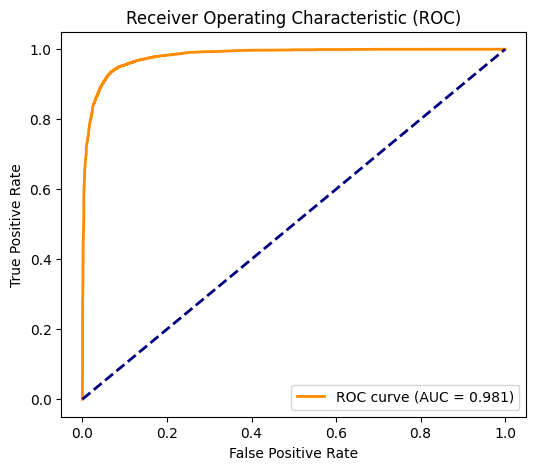

ROC curve saved to results/roc_curve.png


In [18]:
from sklearn.metrics import roc_curve, auc
import torch.nn.functional as F
import torch
import matplotlib.pyplot as plt

# Get probabilities by applying softmax to the raw logits
probs = F.softmax(torch.tensor(predictions.predictions), dim=-1).numpy()
positive_probs = probs[:, 1] # Probabilities for the 'positive' class

fpr, tpr, thresholds = roc_curve(y_test_int, positive_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")

# Save for GitHub
plt.savefig("results/roc_curve.png", dpi=300, bbox_inches='tight')
plt.show()
print("ROC curve saved to results/roc_curve.png")

Prediction Confidence Distribution

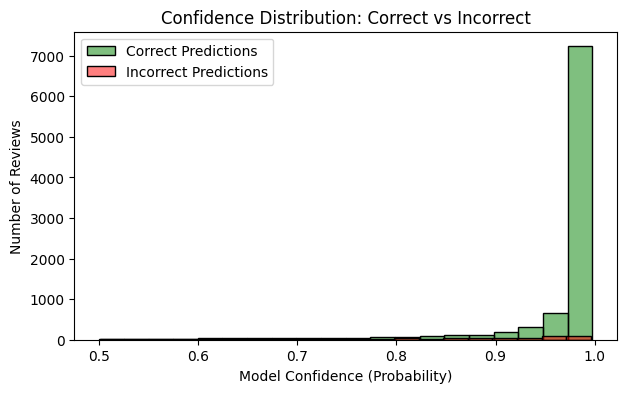

Confidence distribution saved to results/confidence_dist.png


In [19]:
import seaborn as sns
import numpy as np

# Extract the maximum probability (confidence) for each prediction
confidences = np.max(probs, axis=-1)
correct_preds = (y_pred_distilbert == y_test_int)

plt.figure(figsize=(7, 4))
sns.histplot(confidences[correct_preds], bins=20, color='green', alpha=0.5, label='Correct Predictions')
sns.histplot(confidences[~correct_preds], bins=20, color='red', alpha=0.5, label='Incorrect Predictions')
plt.xlabel('Model Confidence (Probability)')
plt.ylabel('Number of Reviews')
plt.title('Confidence Distribution: Correct vs Incorrect')
plt.legend()

# Save for GitHub
plt.savefig("results/confidence_dist.png", dpi=300, bbox_inches='tight')
plt.show()
print("Confidence distribution saved to results/confidence_dist.png")

Error Analysis (Hard Examples)

In [20]:
# Find examples where the model guessed wrong
false_positives = np.where((y_pred_distilbert == 1) & (y_test_int == 0))[0]
false_negatives = np.where((y_pred_distilbert == 0) & (y_test_int == 1))[0]

print("--- Error Analysis ---")
print("\nFalse Positive (True: Negative, Predicted: Positive):")
if len(false_positives) > 0:
    idx = false_positives[0]
    print(f"Model Confidence: {probs[idx, 1]:.4f}")
    print(X_test_raw.iloc[idx][:300] + "...\n")

print("False Negative (True: Positive, Predicted: Negative):")
if len(false_negatives) > 0:
    idx = false_negatives[0]
    print(f"Model Confidence: {probs[idx, 0]:.4f}")
    print(X_test_raw.iloc[idx][:300] + "...")

--- Error Analysis ---

False Positive (True: Negative, Predicted: Positive):
Model Confidence: 0.8683
Despite being a huge fan of Fred Astaire and Ginger Rogers' movies, it wasn't until about 6 years ago that I first saw 'Follow the Fleet'. I knew all the songs from an old Astaire/Rogers record (yes, vinyl) but knew nothing of the plot.<br /><br />Unfortunately, while the songs are catchy and Ginger...

False Negative (True: Positive, Predicted: Negative):
Model Confidence: 0.6171
This isn't exactly a great film, but I admire the writers and director for trying something a little different. The film's main theme is fate and small, seemingly insignificant things that can greatly change the future. In some ways this reminds me of the film SLIDING DOORS, though instead of focusi...


Extended Error Analysis (Truncation and Mixed Sentiment)

In [21]:
import random

# Fix seed for this random sample so it stays reproducible
random.seed(42)

print("--- Extended Error Analysis ---")
print("\nMore False Positives (Model thought it was Good, but it was Bad):")
for idx in random.sample(list(false_positives), 2):
    text = X_test_raw.iloc[idx]
    print(f"Confidence: {probs[idx, 1]:.4f} | Word Count: {len(text.split())}")
    print(f"Start: {text[:150]}...")
    print(f"End: ...{text[-150:]}\n")

print("More False Negatives (Model thought it was Bad, but it was Good):")
for idx in random.sample(list(false_negatives), 2):
    text = X_test_raw.iloc[idx]
    print(f"Confidence: {probs[idx, 0]:.4f} | Word Count: {len(text.split())}")
    print(f"Start: {text[:150]}...")
    print(f"End: ...{text[-150:]}\n")

--- Extended Error Analysis ---

More False Positives (Model thought it was Good, but it was Bad):
Confidence: 0.9508 | Word Count: 628
Start: Although its plot is taken from the history of ancient Rome, 'Caligula' is not made in the style of sword-and-sandal epics like 'Spartacus' or 'Gladia...
End: ...owever, succeed upon any other level, either as art cinema or as a study of the politics of dictatorship. Even seen as erotica it is second-rate. 4/10

Confidence: 0.9074 | Word Count: 154
Start: I don't know how to describe this movie. It's definitely one of the weirdest movies I've seen in a long time. It is very unsettling at times but also ...
End: ...he comment and feel somehow attracted by this kind of entertainment, give it a try!<br /><br />My rating: 4/10 (maybe a little too weird for my taste)

More False Negatives (Model thought it was Bad, but it was Good):
Confidence: 0.6677 | Word Count: 149
Start: Ah, a Kelly/Sinatra sailor-suit musical. So familiar, right? Yes, but this 